# Site 02 · Surface evidence atlas
### Reproducible reconnaissance · Method v3

**วัตถุประสงค์:** แยกพื้นที่ผิวดินที่สังเกตได้จากพืช น้ำ และพื้นที่ก่อสร้าง แล้วตรวจความผิดปกติของอัตราส่วนสเปกตรัมที่เกิดซ้ำหลายวัน ผลเป็นจุดตรวจสอบเบื้องต้น ไม่ใช่การยืนยันแหล่งทอง

This notebook uses a single recent dry-season window, explicit product-XML radiometry, per-date masks, a historical ESA WorldCover reference, temporal persistence, and sensitivity analysis. All dates, thresholds and exclusions are exported. No learned gold model or calibrated probability is claimed.

**Changes from previous runs:** one season replaces mixed years; optical bands use average resampling and SCL uses nearest; two ratio percentile ranks replace the weighted brightness score; connected-component area filtering replaces opening/closing. These changes make counts incomparable to previous T/R labels. A positive result is not independent validation. Empty outputs are valid.

Run all cells. Outputs go to `../03_Data` when run from the `04_Notebook` directory. Internet is required on the first run. Set `REFRESH=True` to query the catalogue again; otherwise saved scene IDs and input cache are reused.

Coordinate basis: user table, WGS84 / UTM Zone 47N as proposed and accepted to proceed in chat. The screenshot does not state a CRS. Polygon order is source points 1–2–4–3. Projected area 43.0528 km². Validate the CRS against the source survey or a known ground point before navigation. Site name is an identifier, not a verified administrative location.

In [1]:
%pip -q install pystac-client planetary-computer stackstac rioxarray geopandas scipy matplotlib pandas numpy requests nbformat


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import warnings
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from IPython.display import display, HTML
from pystac_client import Client
import planetary_computer as pc
import stackstac
import rioxarray
import rasterio
from rasterio.enums import Resampling
from rasterio.features import geometry_mask, shapes
from rasterio.plot import plotting_extent
from scipy.ndimage import binary_dilation, label
from shapely.geometry import Polygon, shape
from shapely.ops import unary_union
import requests

OUT = Path.cwd().parent / "03_Data"
OUT.mkdir(parents=True, exist_ok=True)
CACHE = Path.cwd() / "inputs"
CACHE.mkdir(exist_ok=True)
REFRESH = False
CFG = dict(version="3.0", dates="2025-11-01/2026-04-30", epsg=32647, resolution_m=20,
           max_dates=8, ndvi_max=0.30, min_observations=3, exposed_fraction=0.60,
           ratio_quantile=0.90, anomaly_fraction=0.67, min_pixels=8,
           cloud_buffer_pixels=1, denominator_floor=0.01)
BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]
BAND_IDS = dict(zip(BANDS, [1, 2, 3, 7, 11, 12]))
coords = [(101.61064483616188, 18.287248197868195), (101.67627600957, 18.286339927877865), (101.6754181163146, 18.230363299536947), (101.60980792232279, 18.231268599021476)]
aoi = Polygon(coords)
assert aoi.is_valid and not aoi.is_empty
aoi_gdf = gpd.GeoDataFrame({"name":["Site 02"]}, geometry=[aoi], crs=4326)
aoi_utm = aoi_gdf.to_crs(CFG["epsg"])
area_km2 = aoi_utm.area.iloc[0] / 1e6
catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")
print(f"AOI {area_km2:.3f} km² | season {CFG['dates']} | 20 m analysis grid")

AOI 43.053 km² | season 2025-11-01/2026-04-30 | 20 m analysis grid


## 1 · Acquisition and provenance
Select full-AOI acquisitions, prefer the latest processing baseline for duplicate days, and take a low-cloud acquisition from each month before filling to eight dates. Tile-wide cloud fraction is only a selection aid; AOI quality is measured per scene below. Fixed scene IDs and cached calibrated arrays make subsequent runs reproducible.

In [3]:
selection_file = CACHE / "selection.json"
if selection_file.exists() and not REFRESH:
    selection = json.loads(selection_file.read_text())
    assert selection["dates"] == CFG["dates"], "Change REFRESH to update the scene selection"
    items = [catalog.get_collection("sentinel-2-l2a").get_item(i) for i in selection["ids"]]
else:
    found = list(catalog.search(collections=["sentinel-2-l2a"], intersects=aoi.__geo_interface__,
        datetime=CFG["dates"], query={"eo:cloud_cover":{"lt":35}}).items())
    found = [i for i in found if shape(i.geometry).intersection(aoi).area / aoi.area >= 0.99]
    assert found, "No full-AOI scenes in the configured season"
    rows = pd.DataFrame([dict(id=i.id, date=i.datetime.date().isoformat(), month=i.datetime.strftime("%Y-%m"),
        baseline=float(i.properties["s2:processing_baseline"]), cloud=i.properties["eo:cloud_cover"]) for i in found])
    rows = rows.sort_values(["baseline","cloud"], ascending=[False,True]).drop_duplicates("date")
    monthly = rows.sort_values("cloud").drop_duplicates("month")
    chosen = pd.concat([monthly, rows.sort_values("cloud")]).drop_duplicates("date").head(CFG["max_dates"])
    items = sorted([i for i in found if i.id in chosen.id.tolist()], key=lambda i:i.datetime)
    selection = {"dates":CFG["dates"], "ids":[i.id for i in items]}
    selection_file.write_text(json.dumps(selection, indent=2))
assert len(items) >= CFG["min_observations"]
input_key = hashlib.sha256(json.dumps({"selection":selection,"coords":coords,"grid":CFG["resolution_m"],"reader":"xml-average-v3"}, sort_keys=True).encode()).hexdigest()[:16]
cube_file = CACHE / f"cube_{input_key}.npz"
cal_file = CACHE / f"calibration_{input_key}.json"
if cube_file.exists() and cal_file.exists() and not REFRESH:
    cached = np.load(cube_file)
    reflectance, scl, x, y = [cached[k] for k in ["reflectance","scl","x","y"]]
    calibration = json.loads(cal_file.read_text())
else:
    signed = [pc.sign(i) for i in items]
    optical = stackstac.stack(signed, assets=BANDS, bounds_latlon=aoi.bounds, epsg=CFG["epsg"],
        resolution=20, rescale=False, dtype="float64", resampling=Resampling.average).compute()
    classes = stackstac.stack(signed, assets=["SCL"], bounds_latlon=aoi.bounds, epsg=CFG["epsg"],
        resolution=20, rescale=False, dtype="float64", resampling=Resampling.nearest).compute()
    assert np.array_equal(optical.id, classes.id) and np.array_equal(optical.x, classes.x) and np.array_equal(optical.y, classes.y)
    assert optical.id.values.tolist() == [i.id for i in sorted(items,key=lambda i:i.datetime)]
    by_id = {i.id:i for i in items}
    calibration = {}
    for item_id in optical.id.values.tolist():
        item = by_id[item_id]
        response = requests.get(pc.sign(item.assets["product-metadata"].href), timeout=60)
        response.raise_for_status()
        xml = response.content
        (CACHE / f"{item.id}.xml").write_bytes(xml)
        elements = list(ET.fromstring(xml).iter())
        q = next(float(e.text) for e in elements if e.tag.split("}")[-1] == "BOA_QUANTIFICATION_VALUE")
        offsets = {int(e.attrib["band_id"]):float(e.text) for e in elements if e.tag.split("}")[-1] == "BOA_ADD_OFFSET"}
        assert q > 0 and all(b in offsets for b in BAND_IDS.values())
        calibration[item_id] = dict(quantification=q, offsets={b:offsets[BAND_IDS[b]] for b in BANDS}, xml_sha256=hashlib.sha256(xml).hexdigest())
    raw = optical.values
    offset = np.array([[calibration[i]["offsets"][b] for b in BANDS] for i in optical.id.values])[:,:,None,None]
    q = np.array([calibration[i]["quantification"] for i in optical.id.values])[:,None,None,None]
    reflectance = np.where(raw > 0, (raw + offset) / q, np.nan).astype("float32")
    scl = classes.values[:,0]
    x, y = optical.x.values, optical.y.values
    np.savez_compressed(cube_file, reflectance=reflectance, scl=scl, x=x, y=y)
    cal_file.write_text(json.dumps(calibration, indent=2))
items = sorted(items, key=lambda i:i.datetime)
assert len(calibration) == reflectance.shape[0] == len(items)
transform = rasterio.transform.from_origin(x[0]-10, y[0]+10, 20, 20)
grid_shape = scl.shape[1:]
inside = geometry_mask(aoi_utm.geometry, out_shape=grid_shape, transform=transform, invert=True)
pixel_ha = 0.04
assert abs(inside.sum()*0.0004-area_km2)/area_km2 < 0.02
dates = [i.datetime.date().isoformat() for i in items]
print("Independent acquisition days:", dates)

Independent acquisition days: ['2025-11-21', '2025-12-01', '2025-12-03', '2026-01-12', '2026-01-20', '2026-02-04', '2026-03-26', '2026-04-10']


## 2 · Land cover and observation quality
ESA WorldCover 2021 is a historical **land-cover reference**, not current land use. Its globally reported 76.7% overall accuracy is not a site accuracy estimate. At 20 m the categorical reference is resampled by nearest neighbour. Tree cover, cropland, built surfaces, water and wetlands are conservatively excluded; shrub/grass/bare classes require repeated Sentinel exposed observations. This may miss recently cleared or seasonally exposed ground. Unknown reference classes are excluded.

SCL=5 plus NDVI < 0.30, NDWI < 0 and positive reflectance are required per date. Cloud/shadow/unclassified pixels receive a one-pixel buffer. At least three exposures and exposure on 60% of clear-land dates are required. These are explicit screening assumptions, not validated universal thresholds.

In [4]:
wc_items = list(catalog.search(collections=["esa-worldcover"], intersects=aoi.__geo_interface__).items())
wc_items = [i for i in wc_items if "2021_v200" in i.id]
assert wc_items, "WorldCover 2021 unavailable; do not silently omit the land-cover check"
wc_file = CACHE / f"worldcover_{input_key}.npy"
if wc_file.exists() and not REFRESH:
    cover = np.load(wc_file)
else:
    wc_stack = stackstac.stack([pc.sign(i) for i in wc_items], assets=["map"], bounds_latlon=aoi.bounds,
        epsg=CFG["epsg"], resolution=20, rescale=False, resampling=Resampling.nearest).compute()
    cover = np.nanmax(wc_stack.values[:,0], axis=0)
    assert np.array_equal(wc_stack.x, x) and np.array_equal(wc_stack.y, y)
    np.save(wc_file, cover)
names = {10:"Tree cover",20:"Shrubland",30:"Grassland",40:"Cropland",50:"Built-up",60:"Bare / sparse",
         70:"Snow / ice",80:"Permanent water",90:"Herbaceous wetland",95:"Mangrove",100:"Moss / lichen"}
landcover_table = pd.DataFrame([dict(code=k, land_cover=v, area_ha=float(((cover==k)&inside).sum()*pixel_ha)) for k,v in names.items()])
landcover_table["aoi_percent"] = landcover_table.area_ha / (inside.sum()*pixel_ha)*100
landcover_table.to_csv(OUT/"landcover_2021.csv", index=False)
blue, green, red, nir, swir1, swir2 = [reflectance[:,j] for j in range(6)]
def ratio(a,b):
    return np.divide(a,b,out=np.full_like(a,np.nan),where=np.isfinite(a)&np.isfinite(b)&(b>CFG["denominator_floor"]))
ndvi = ratio(nir-red, nir+red)
ndwi = ratio(green-nir, green+nir)
bad = ~np.isin(scl,[4,5,6])
buffered = np.stack([binary_dilation(v,iterations=CFG["cloud_buffer_pixels"]) for v in bad])
positive = np.all(np.isfinite(reflectance)&(reflectance>0),axis=1)
clear = np.isin(scl,[4,5]) & ~buffered & positive & inside
reference_allowed = np.isin(cover,[20,30,60]) & inside
dynamic_exposed = clear & (scl==5) & (ndvi<CFG["ndvi_max"]) & (ndwi<0) & (swir1>0.02)
dynamic_support = dynamic_exposed.sum(axis=0)
dynamic_eligible = (dynamic_support>=CFG["min_observations"]) & (dynamic_support/np.maximum(clear.sum(axis=0),1)>=CFG["exposed_fraction"]) & inside
cover_disagreement = dynamic_eligible & ~reference_allowed
coverage_audit = pd.DataFrame([
    dict(category="Repeated exposed surface before historical-cover veto",area_ha=dynamic_eligible.sum()*pixel_ha),
    dict(category="Historical-cover disagreement: manual review required",area_ha=cover_disagreement.sum()*pixel_ha),
    dict(category="Repeated exposed surface retained by reference",area_ha=(dynamic_eligible&reference_allowed).sum()*pixel_ha)])
coverage_audit.to_csv(OUT/"coverage_audit.csv",index=False)
def eligibility(ndvi_limit):
    exposed = clear & (scl==5) & (ndvi<ndvi_limit) & (ndwi<0) & (swir1>0.02) & reference_allowed
    support = exposed.sum(axis=0)
    fraction = support / np.maximum(clear.sum(axis=0),1)
    eligible = (support>=CFG["min_observations"]) & (fraction>=CFG["exposed_fraction"]) & inside
    return exposed,support,fraction,eligible
exposed,support,exposure_fraction,eligible = eligibility(CFG["ndvi_max"])
scene_qa = pd.DataFrame([dict(item_id=i.id,date=dates[t],baseline=i.properties["s2:processing_baseline"],
    tile_cloud_pct=i.properties["eo:cloud_cover"],aoi_clear_land_pct=100*clear[t].sum()/inside.sum(),
    aoi_exposed_pct=100*exposed[t].sum()/inside.sum()) for t,i in enumerate(items)])
scene_qa.to_csv(OUT/"scene_quality.csv",index=False)
display(scene_qa.round(3))
display(landcover_table[landcover_table.area_ha>0].round(3))

,item_id,date,baseline,tile_cloud_pct,aoi_clear_land_pct,aoi_exposed_pct
0,S2C_MSIL2A_20251121T034501_R061_T47QQA_2025112...,2025-11-21,05.11,3.937,99.698,0.017
1,S2C_MSIL2A_20251201T034131_R061_T47QQA_2025120...,2025-12-01,05.11,0.001,99.683,0.021
2,S2A_MSIL2A_20251203T034201_R061_T47QQA_2025120...,2025-12-03,05.11,0.022,99.638,0.024
3,S2A_MSIL2A_20260112T034201_R061_T47QQA_2026011...,2026-01-12,05.11,0.022,100.000,0.075
4,S2C_MSIL2A_20260120T034051_R061_T47QQA_2026012...,2026-01-20,05.11,0.000,99.495,0.066
5,S2B_MSIL2A_20260204T033839_R061_T47QQA_2026020...,2026-02-04,05.12,0.266,99.562,0.099
6,S2B_MSIL2A_20260326T033529_R061_T47QQA_2026032...,2026-03-26,05.12,0.033,99.668,0.129
7,S2C_MSIL2A_20260410T033531_R061_T47QQA_2026041...,2026-04-10,05.12,0.002,98.680,0.168


,code,land_cover,area_ha,aoi_percent
0,10,Tree cover,4138.08,96.362
2,30,Grassland,124.68,2.903
3,40,Cropland,31.44,0.732
7,80,Permanent water,0.12,0.003


## 3 · Repeat spectral evidence and sensitivity
Calculate B04/B02 and B11/B12 on each date before compositing. Their interpretation is broad ferric/OH-related **proxy contrast**, which can also reflect soil, moisture, weathering and human disturbance. They do not identify mineral species.

Percentile ranks use only that date's eligible exposed AOI pixels. Both ratios must exceed the 90th percentile on at least three dates and on ≥67% of scored exposed dates. A date needs at least 30 finite comparison pixels with nonzero range to be scored; unavailable scores are not negative observations. The displayed score is the median of the weaker of the two percentile ranks. No brightness bonus or terrain-derived confidence is applied. Minimum area is eight edge-connected pixels (0.32 ha); no morphology adds pixels or bridges gaps.

The percentile criterion produces relative highs by design. Sensitivity to NDVI and percentile thresholds is exported; stability measures repeatability, not truth or gold probability.

In [5]:
def percentile_ranks(values, mask):
    result = np.full(values.shape,np.nan,dtype="float32")
    sample = values[mask & np.isfinite(values)]
    if len(sample)>=30 and np.ptp(sample)>0:
        ordered = np.sort(sample)
        result[mask] = np.searchsorted(ordered,values[mask],side="right") / len(ordered)
    return result
def area_filter(mask,min_pixels):
    labels,n = label(mask)
    sizes = np.bincount(labels.ravel())
    keep = (labels>0)&(sizes[labels]>=min_pixels)
    return keep,labels,int(np.unique(labels[keep]).size)
ferric = ratio(red,blue)
oh = ratio(swir1,swir2)
def evidence(ndvi_limit,quantile):
    ex,n,frac,el = eligibility(ndvi_limit)
    ranks_a = np.stack([percentile_ranks(ferric[t],ex[t]&el) for t in range(len(items))])
    ranks_b = np.stack([percentile_ranks(oh[t],ex[t]&el) for t in range(len(items))])
    scored = np.isfinite(ranks_a)&np.isfinite(ranks_b)&ex
    score_support = scored.sum(axis=0)
    hits = ((ranks_a>=quantile)&(ranks_b>=quantile)&scored).sum(axis=0)
    persistence = np.where(score_support>=CFG["min_observations"],hits/np.maximum(score_support,1),np.nan)
    raw = el & (hits>=CFG["min_observations"]) & (persistence>=CFG["anomaly_fraction"])
    mask,labels,count = area_filter(raw,CFG["min_pixels"])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore",RuntimeWarning)
        score = np.nanmedian(np.minimum(ranks_a,ranks_b),axis=0)
    scored_dates = int(np.isfinite(ranks_a).any(axis=(1,2)).sum())
    return dict(mask=mask,labels=labels,count=count,raw=raw,score=score,hits=hits,persistence=persistence,eligible=el,scored_dates=scored_dates,score_support=score_support)
base = evidence(CFG["ndvi_max"],CFG["ratio_quantile"])
sensitivity = []
for nd in [0.20,0.30,0.40]:
    for quantile in [0.85,0.90,0.95]:
        run = evidence(nd,quantile)
        union = (run["mask"]|base["mask"]).sum()
        sensitivity.append(dict(ndvi_max=nd,ratio_percentile=quantile,eligible_ha=run["eligible"].sum()*pixel_ha,
            raw_anomaly_ha=run["raw"].sum()*pixel_ha,polygon_count=run["count"],area_ha=run["mask"].sum()*pixel_ha,
            scored_dates=run["scored_dates"],evaluation_status="evaluated" if run["scored_dates"]>=CFG["min_observations"] else "insufficient_score_samples",
            baseline_iou=float((run["mask"]&base["mask"]).sum()/union) if union else None))
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(OUT/"sensitivity.csv",index=False)
display(sensitivity.round(3))
records = []
for zone in np.unique(base["labels"][base["mask"]]):
    m = (base["labels"]==zone)&base["mask"]
    geom = unary_union([shape(g) for g,v in shapes(m.astype("uint8"),mask=m,transform=transform) if v==1])
    records.append(dict(observation_id=f"S02-{int(zone):03d}",area_ha=geom.area/10000,
        relative_score=float(np.nanmean(base["score"][m])),exposed_dates_mean=float(support[m].mean()),
        anomalous_dates_min=int(base["hits"][m].min()),scored_dates_min=int(base["score_support"][m].min()),repeat_fraction=float(base["persistence"][m].mean()),
        status="unvalidated_surface_observation",geometry=geom))
columns=["observation_id","area_ha","relative_score","exposed_dates_mean","anomalous_dates_min","scored_dates_min","repeat_fraction","status","geometry"]
observations = gpd.GeoDataFrame(records,columns=columns,geometry="geometry",crs=CFG["epsg"])
points = observations.geometry.representative_point().to_crs(4326)
observations["longitude"] = points.x
observations["latitude"] = points.y
observations.drop(columns="geometry").to_csv(OUT/"observations.csv",index=False)
if observations.empty:
    (OUT/"observations.geojson").write_text(json.dumps({"type":"FeatureCollection","features":[]}))
else:
    observations.to_crs(4326).to_file(OUT/"observations.geojson",driver="GeoJSON")
print(f"Baseline: {len(observations)} polygons, {base['mask'].sum()*pixel_ha:.2f} ha")

,ndvi_max,ratio_percentile,eligible_ha,raw_anomaly_ha,polygon_count,area_ha,scored_dates,evaluation_status,baseline_iou
0,0.2,0.85,1.84,0.00,0,0.0,5,evaluated,None
1,0.2,0.90,1.84,0.00,0,0.0,5,evaluated,None
2,0.2,0.95,1.84,0.00,0,0.0,5,evaluated,None
3,0.3,0.85,2.68,0.04,0,0.0,5,evaluated,None
4,0.3,0.90,2.68,0.00,0,0.0,5,evaluated,None
5,0.3,0.95,2.68,0.00,0,0.0,5,evaluated,None
6,0.4,0.85,4.44,0.04,0,0.0,8,evaluated,None
7,0.4,0.90,4.44,0.00,0,0.0,8,evaluated,None
8,0.4,0.95,4.44,0.00,0,0.0,8,evaluated,None


Baseline: 0 polygons, 0.00 ha


## 4 · GIS layers, readable atlas, and field record
Maps share one 20 m grid and correct pixel-edge extents. Historical land cover is displayed separately from current observation eligibility. Outside AOI and unavailable measurements are explicit. Polygons are unvalidated observations, with no tier label or inferred gold grade. A blank field form is provided for independent reference observations and eventual laboratory results.

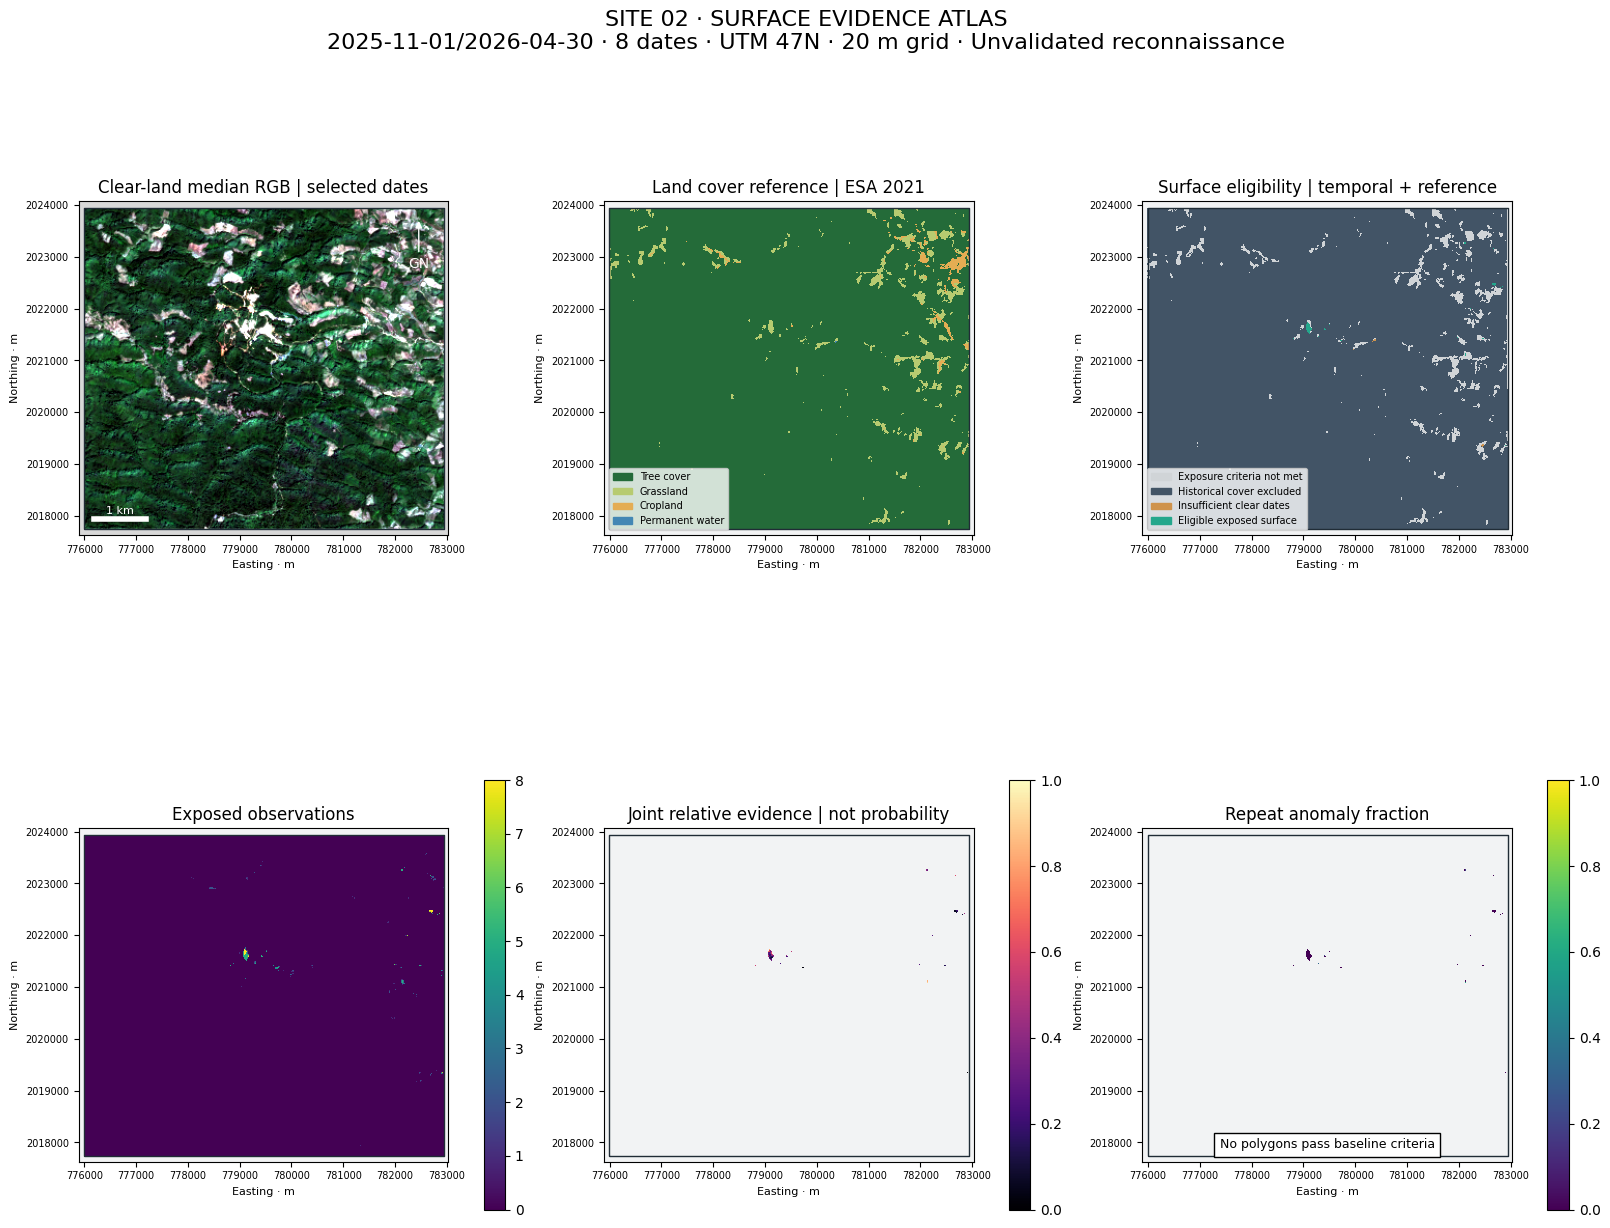

In [6]:
def write_raster(name,array,description):
    values = np.where(inside,array,np.nan).astype("float32")
    with rasterio.open(OUT/name,"w",driver="GTiff",height=grid_shape[0],width=grid_shape[1],count=1,
        dtype="float32",crs=f"EPSG:{CFG['epsg']}",transform=transform,nodata=np.nan,compress="deflate") as dst:
        dst.write(values,1)
        dst.set_band_description(1,description)
        dst.update_tags(method_version=CFG["version"],status="unvalidated_reconnaissance")
layers = {"landcover_2021.tif":(cover,"ESA WorldCover 2021 class; nearest at 20 m"),
          "historical_cover_disagreement.tif":(cover_disagreement,"Repeated current exposure excluded by historical reference; requires review"),
          "clear_observations.tif":(clear.sum(axis=0),"Clear land acquisition count"),
          "exposed_observations.tif":(support,"Exposed acquisition count"),
          "eligible_surface.tif":(eligible,"1 eligible, 0 excluded within AOI"),
          "relative_evidence.tif":(base["score"],"Median joint proxy percentile rank, not probability"),
          "scored_observations.tif":(base["score_support"],"Dates with sufficient finite comparison pixels"),
          "repeat_fraction.tif":(np.where(eligible,base["persistence"],np.nan),"Anomalous dates / scored exposed dates; missing is not negative"),
          "candidate_pixels.tif":(base["mask"],"1 retained observation, 0 no retained observation")}
for name,(array,description) in layers.items():
    write_raster(name,array,description)
with warnings.catch_warnings():
    warnings.simplefilter("ignore",RuntimeWarning)
    rgb = np.nanmedian(np.where(clear[:,None],reflectance[:,[2,1,0]],np.nan),axis=0).transpose(1,2,0)
rgb_display = np.zeros_like(rgb)
for channel in range(3):
    values = rgb[:,:,channel]
    lo,hi = np.nanpercentile(values[inside],[2,98])
    rgb_display[:,:,channel] = np.clip((values-lo)/max(hi-lo,1e-6),0,1)
rgb_display = np.nan_to_num(rgb_display,nan=0.85)
extent = plotting_extent(np.zeros(grid_shape),transform)
cover_codes = list(names)
cover_colors = ["#246b39","#b49c37","#b7cb70","#e4ad53","#bd5656","#c4b99f","#fafafa","#4387b4","#55bdb0","#13675a","#adb59b"]
cover_index = np.full(grid_shape,np.nan)
for j,k in enumerate(cover_codes): cover_index[(cover==k)&inside]=j
surface_status = np.full(grid_shape,np.nan)
surface_status[inside]=0
surface_status[inside & ~reference_allowed]=1
surface_status[inside & reference_allowed & (clear.sum(axis=0)<CFG["min_observations"])]=2
surface_status[eligible]=3
fig,axes = plt.subplots(2,3,figsize=(16,13),constrained_layout=True)
axes[0,0].imshow(rgb_display,extent=extent)
axes[0,0].set_title("Clear-land median RGB | selected dates")
axes[0,1].imshow(cover_index,extent=extent,cmap=ListedColormap(cover_colors),vmin=-0.5,vmax=10.5,interpolation="nearest")
axes[0,1].set_title("Land cover reference | ESA 2021")
axes[0,1].legend(handles=[Patch(color=cover_colors[j],label=names[k]) for j,k in enumerate(cover_codes) if ((cover==k)&inside).any()],loc="lower left",fontsize=7)
axes[0,2].imshow(surface_status,extent=extent,cmap=ListedColormap(["#d0d4d7","#425466","#cf934c","#24a78c"]),vmin=-0.5,vmax=3.5,interpolation="nearest")
axes[0,2].set_title("Surface eligibility | temporal + reference")
axes[0,2].legend(handles=[Patch(color=col,label=lab) for col,lab in zip(["#d0d4d7","#425466","#cf934c","#24a78c"],["Exposure criteria not met","Historical cover excluded","Insufficient clear dates","Eligible exposed surface"])],loc="lower left",fontsize=7)
for ax,array,title,cmap,vmax in [(axes[1,0],np.where(inside,support,np.nan),"Exposed observations","viridis",len(items)),
    (axes[1,1],np.where(inside,base["score"],np.nan),"Joint relative evidence | not probability","magma",1),
    (axes[1,2],np.where(eligible,base["persistence"],np.nan),"Repeat anomaly fraction","viridis",1)]:
    im=ax.imshow(array,extent=extent,cmap=cmap,vmin=0,vmax=vmax,interpolation="nearest")
    fig.colorbar(im,ax=ax,shrink=0.7)
    ax.set_title(title)
for ax in axes.flat:
    aoi_utm.boundary.plot(ax=ax,color="#202c36",linewidth=1)
    ax.set_facecolor("#f2f3f4")
    ax.set_xlim(extent[:2]);ax.set_ylim(extent[2:])
    ax.ticklabel_format(style="plain",useOffset=False)
    ax.tick_params(labelsize=7)
    ax.set_xlabel("Easting · m",fontsize=8);ax.set_ylabel("Northing · m",fontsize=8)
    ax.set_aspect("equal")
axes[0,0].annotate("GN",xy=(0.92,0.95),xytext=(0.92,0.80),xycoords="axes fraction",ha="center",color="white",arrowprops={"arrowstyle":"-|>","color":"white"})
bar_x,bar_y=extent[0]+300,extent[2]+300
axes[0,0].plot([bar_x,bar_x+1000],[bar_y,bar_y],color="white",linewidth=4)
axes[0,0].text(bar_x+500,bar_y+100,"1 km",ha="center",color="white",fontsize=8)
if not observations.empty:
    observations.boundary.plot(ax=axes[1,2],color="#ee653c",linewidth=1.5)
    for _,row in observations.iterrows():
        p=row.geometry.representative_point()
        axes[1,2].annotate(row.observation_id,(p.x,p.y),fontsize=7,bbox={"facecolor":"white","alpha":0.8})
else:
    axes[1,2].text(0.5,0.04,"No polygons pass baseline criteria",transform=axes[1,2].transAxes,ha="center",fontsize=9,bbox={"facecolor":"white"})
fig.suptitle(f"SITE 02 · SURFACE EVIDENCE ATLAS\n{CFG['dates']} · {len(items)} dates · UTM 47N · 20 m grid · Unvalidated reconnaissance",fontsize=16)
fig.savefig(OUT/"atlas.png",dpi=180,facecolor="white")
plt.show()
field_columns=["sample_id","observation_id","date_utc","longitude","latitude","location_accuracy_m","surface_cover_observed","rock_soil_description","photo_id","sample_type","laboratory","assay_method","au_value","au_unit","detection_limit","qa_qc_type","chain_of_custody_id","notes"]
pd.DataFrame(columns=field_columns).to_csv(OUT/"field_records_template.csv",index=False)

## 5 · Verification, provenance and limitations
Automated checks validate radiometry, mask containment, area conservation, edge-connected polygonization, repeat support, and export counts. They do **not** measure mineral or land-cover accuracy. A site-labelled test set and geochemical assays are absent. No numerical gold confidence is reported.

In [7]:
assert abs((2000-1000)/10000-0.1)<1e-9
toy = np.zeros((8,8),bool);toy[1:3,1:5]=True;toy[6,6]=True
toy_keep,_,toy_count=area_filter(toy,8)
assert toy_keep.sum()==8 and toy_count==1 and not toy_keep[6,6]
assert not (base["mask"] & ~eligible).any()
assert not (eligible & ~inside).any()
assert not (base["mask"] & (base["hits"]<CFG["min_observations"])).any()
assert np.isclose(observations.area_ha.sum(),base["mask"].sum()*pixel_ha)
assert len(json.loads((OUT/"observations.geojson").read_text())["features"])==len(observations)
for name in layers:
    with rasterio.open(OUT/name) as src:
        assert src.shape==grid_shape and src.crs.to_epsg()==CFG["epsg"] and src.transform==transform
sources = [
    dict(title="Sentinel-2 processing",url="https://sentiwiki.copernicus.eu/web/s2-processing",use="Product radiometry and quality",limit="Calibration is not mineral validation"),
    dict(title="ESA WorldCover",url="https://esa-worldcover.org/en/about/objectives",use="Historical 2021 land cover, global accuracy 76.7%",limit="Not current land use or site accuracy"),
    dict(title="Duolong multisensor alteration study",url="https://www.sciencedirect.com/science/article/abs/pii/S0169136818301173",use="Literature context; abstract/search excerpt only",limit="Full publisher text not retrieved; arid study is not Laos validation"),
    dict(title="CLMTV Lao DGM presentation, 2016",url="https://www.dmr.go.th/wp-content/uploads/2023/02/01-Lao-PDR_CLMTV.pdf",use="Regional geological context and map availability",limit="Regional map scale cannot validate this AOI's observations")]
manifest = dict(method=CFG,generated_utc=datetime.now(timezone.utc).isoformat(),status="UNVALIDATED_RECONNAISSANCE",
    aoi_coordinates=coords,aoi_vector_km2=float(area_km2),aoi_grid_km2=float(inside.sum()*0.0004),
    eligible_area_ha=float(eligible.sum()*pixel_ha),eligible_aoi_pct=float(100*eligible.sum()/inside.sum()),
    polygon_count=len(observations),polygon_area_ha=float(base["mask"].sum()*pixel_ha),
    scored_dates=base["scored_dates"],historical_cover_disagreement_ha=float(cover_disagreement.sum()*pixel_ha),
    dates=dates,scene_ids=[i.id for i in items],worldcover_ids=[i.id for i in wc_items],
    radiometry=calibration,source_catalog="https://planetarycomputer.microsoft.com/api/stac/v1",
    input_cube_sha256=hashlib.sha256(cube_file.read_bytes()).hexdigest(),
    packages={p:importlib.metadata.version(p) for p in ["numpy","pandas","geopandas","rasterio","stackstac","scipy","pystac-client","planetary-computer","rioxarray"]},
    coordinate_basis=json.loads((OUT/"coordinate_basis.json").read_text()),
    ground_validation="Not available; no assays or independent site labels",sources=sources,
    checks="passed: calibration metadata, grid, AOI containment, connected area, support, exported feature count")
(OUT/"manifest.json").write_text(json.dumps(manifest,indent=2))
(OUT/"requirements-lock.txt").write_text("\n".join(f"{k}=={v}" for k,v in manifest["packages"].items())+"\n")
pd.DataFrame(sources).to_csv(OUT/"sources.csv",index=False)
summary = f"""<html><head><meta charset="utf-8"><title>Site 02 evidence atlas</title>
<style>body{{font:16px system-ui;max-width:1150px;margin:40px auto;padding:0 24px;color:#243746}}h1{{font-size:32px}}table{{border-collapse:collapse;font-size:13px}}td,th{{padding:8px;border-bottom:1px solid #ddd}}img{{width:100%}}.note{{padding:18px;background:#eff5f5}}</style></head><body>
<h1>Site 02 · Surface evidence</h1><p>{CFG['dates']} · {len(items)} acquisition days · Method {CFG['version']}</p>
<p class="note">พื้นที่ผิวเปิดที่ผ่านเกณฑ์ {manifest['eligible_area_ha']:.2f} ha ({manifest['eligible_aoi_pct']:.2f}% ของ AOI) · กลุ่มที่ผ่านเกณฑ์ {len(observations)} กลุ่ม<br>ผลสำรวจเบื้องต้น ยังไม่มีข้อมูลภาคสนามหรือผลแล็บยืนยันทอง ผลว่างไม่ได้แปลว่าไม่มีทอง</p>
<img src="atlas.png" alt="Land cover, exposed surfaces and repeat spectral evidence">
<h2>Scene quality</h2>{scene_qa.round(3).to_html(index=False)}
<h2>Historical land cover · 2021</h2>{landcover_table[landcover_table.area_ha>0].round(3).to_html(index=False)}
<h2>Coverage trade-off</h2>{coverage_audit.round(3).to_html(index=False)}
<p>Historical-cover disagreements are exported as a separate raster for manual inspection, not as mineral targets. Insufficient scoring samples are reported explicitly in sensitivity results; an empty output under that condition is not an evaluated negative.</p>
<h2>Sensitivity</h2>{sensitivity.round(3).to_html(index=False,na_rep='undefined (both empty)')}
<h2>Interpretation</h2><p>Repeat anomalies may be soil, weathered material, moisture differences or disturbance. NDVI/SCL is not a complete land-use classification. WorldCover is dated 2021; canopy, crop and built exclusions are conservative. The season is historical, not a live site assessment. Thresholds are analyst assumptions, and no accuracy claim is calibrated against local gold samples.</p>
<p>Regional Lao DGM sources establish geological context only. No verified in-AOI gold occurrences or site geological polygons were acquired in this research. No gold-deposit layer is fabricated. Obtain a georeferenced site geology map and independent assay records to progress from screening to a prospectivity model.</p>
<h2>Audit</h2><p>{manifest['checks']}. Source IDs, XML hashes, package versions and configuration are in manifest.json. This is a new AOI; no targets from the previous site are transferred.</p>
<h2>Sources and scope</h2>{pd.DataFrame(sources).to_html(index=False,render_links=True)}
</body></html>"""
(OUT/"report.html").write_text(summary)
display(HTML(f"<b>Completed:</b> {len(observations)} unvalidated observation polygons. Eligible AOI: {manifest['eligible_aoi_pct']:.2f}%.<br>Report: {OUT/'report.html'}"))